<a href="https://colab.research.google.com/github/young-suh/ESAA_2026/blob/main/week6_note_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **4.3 앙상블 학습**

**앙상블 학습:** 여러 분류기를 생성하고 예측을 결합해서 보다 정확한 최종 예측을 도출하는 기법

목표: 다양한 분류기의 예측 결과를 결합해서 단일 분류기보다 신뢰성이 높은 예측값을 얻는 것

<앙상블 학습의 유형>

**\- 보팅(Voting):** 서로 다른 알고리즘을 가진 분류기를 결합하여 투표를 통해 최종 예측 결과를 결정하는 방식

**\- 배깅(Bagging):** 각 분류기가 모두 같은 알고리즘 기반이지만 데이터 샘플링을 다르게 가져가면서 학습을 수행해 보팅을 수행하는 방식
 - 랜덤 포레스트 알고리즘: 대표적인 배깅 방식

- 배깅 앙상블 방식: 부트스트래핑으로 샘플링된 데이터 세트에 학습을 통해 개별적으로 예측한 결과를 보팅을 통해 최종 예측 결과를 선정하는 방식 (부트스트래핑: 개별 classifier에게 데이터를 샘플링해서 추출하는 방식)

**\- 부스팅(Boosting):** 여러 개의 분류기가 순차적으로 학습하되, 예측이 틀리면 다음 분류기에 가중치를 부여하면서 학습과 예측을 진행하는 방식
- 대표적인 모듈: 그래디언트 부스트, XGBoost(eXtra Gradient Boost), LightGBM(Light Gradient Boost)

### **\# 보팅 유형 - 하드 보팅(Hard Voting)과 소프트 보팅(Soft Voting)**

**하드 보팅:** 다수의 분류기가 결정한 예측값을 최종 보팅 결괏값으로 선정하는 것

**소프트 보팅:** 분류기들의 레이블 값 결정 확률을 모두 더하고 이를 평균해서 이들 중 확률이 가장 높은 레이블 값을 최종 보팅 결괏값으로 선정

-> 일반적으로 소프트 보팅이 예측 성능이 좋아서 더 많이 사용됨



### **\# 보팅 분류기(Voting Classifier)**

<로지스틱 회귀와 KNN을 기반으로 보팅 분류기를 만들기>

In [1]:
import pandas as pd
from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

cancer = load_breast_cancer()

data_df = pd.DataFrame(cancer.data, columns=cancer.feature_names)
data_df.head(3)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758


<로지스틱 회귀와 KNN을 기반으로 하여 소프트 보팅 방식으로 새롭게 보팅 분류기 만들기>

In [3]:
#개별 모델은 로지스틱 회귀와 KNN임.
lr_clf = LogisticRegression(solver='liblinear')
knn_clf = KNeighborsClassifier(n_neighbors=8)

# 개별 모델을 소프트 보팅 기반의 앙상블 모델로 구현한 분류기
vo_clf = VotingClassifier( estimators=[('LR', lr_clf), ('KNN', knn_clf)], voting= 'soft')
X_train, X_test, y_train, y_test = train_test_split(cancer.data, cancer.target,test_size=0.2, random_state= 156)

# VotingClassifier 학습/예측/평가.
vo_clf.fit(X_train, y_train)
pred = vo_clf.predict(X_test)
print('Voting 분류기 정확도: {0: .4f}'.format(accuracy_score(y_test, pred)))

# 개별 모델의 학습/예측/평가.
classifiers = [lr_clf, knn_clf]
for classifier in classifiers:
  classifier.fit(X_train, y_train)
  pred = classifier.predict(X_test)
  class_name = classifier.__class__.__name__
  print('{0} 정확도: {1: .4f}'.format(class_name, accuracy_score(y_test, pred)))

Voting 분류기 정확도:  0.9561
LogisticRegression 정확도:  0.9474
KNeighborsClassifier 정확도:  0.9386


# **4.4 랜덤 포레스트 **

### **\# 랜덤 포레스트의 개요 및 실습**

- 비교적 빠른 수행 속도
- 다양한 영역에서 높은 예측 성능
- 개별적인 분류기의 기반 알고리즘은 결정트리이지만 개별 트리가 학습하는 데이터 세트는 전체 데이터에서 일부가 중첩되게 샘플링된 데이터 세트임

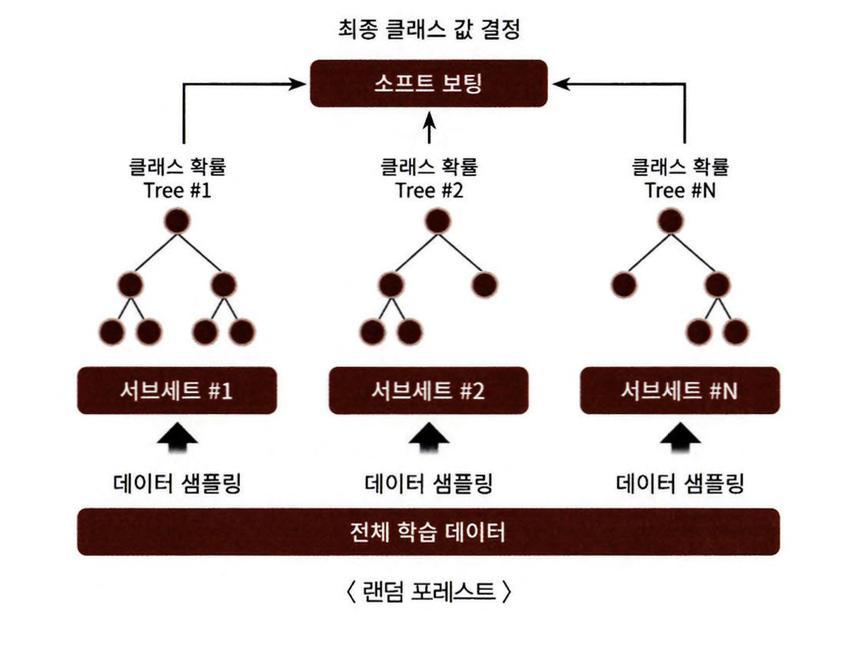

In [6]:
def get_new_feature_name_df(old_feature_name_df):
    feature_dup_df = pd.DataFrame(data=old_feature_name_df.groupby('column_name').cumcount(),columns=['dup_cnt'])
    feature_dup_df = feature_dup_df.reset_index()

    new_feature_name_df = pd.merge(old_feature_name_df.reset_index(),feature_dup_df,how='outer')

    new_feature_name_df['column_name'] = new_feature_name_df[['column_name', 'dup_cnt']].apply(
        lambda x: x[0] + '_' + str(x[1]) if x[1] > 0 else x[0],axis=1)

    new_feature_name_df = new_feature_name_df.drop(['index'], axis=1)

    return new_feature_name_df


def get_human_dataset():
    feature_name_df = pd.read_csv('/content/features.txt', sep='\s+',header=None,names=['column_index', 'column_name'])

    new_feature_name_df = get_new_feature_name_df(feature_name_df)
    feature_name = new_feature_name_df.iloc[:, 1].values.tolist()

    X_train = pd.read_csv('/content/X_train.txt',sep='\s+',names=feature_name)

    X_test = pd.read_csv('/content/X_test.txt',sep='\s+',names=feature_name)

    y_train = pd.read_csv('/content/y_train.txt',sep='\s+',header=None,names=['action'])

    y_test = pd.read_csv('/content/y_test.txt',sep='\s+',header=None,names=['action'])

    return X_train, X_test, y_train, y_test


X_train, X_test, y_train, y_test = get_human_dataset()

In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

# 결정 트리에서 사용한 get_human_dataset( )를 이용해 학습/테스트용 DataFrame 반환
X_train, X_test, y_train, y_test = get_human_dataset()

# 랜덤 포레스트 학습 및 별도의 테스트 세트로 예측 성능 평가
rf_clf = RandomForestClassifier(random_state=0, max_depth=8)
rf_clf.fit(X_train, y_train)
pred = rf_clf.predict(X_test)
accuracy = accuracy_score(y_test, pred)
print('랜덤 포레스트 정확도: {0:.4f}' .format(accuracy))

랜덤 포레스트 정확도: 0.9220


\# 랜덤 포레스트 하이퍼 파라미터 및

- 단점: 하이퍼파라미터가 너무 많고, 그로 인해 튜닝을 위한 시간이 많이 소모됨

- n_estimators: 랜덤 포레스트에서 결정 트리의 개수를 지정, 디폴트는 10개

- max_features는 결정 트리에 사용된 maxjeatures 파라미터와 같음, 기본은 'auto'

- max_depth나 min_samples_leat, min_samples_split와 같이 결정 트리에서 과적합을 개선하기 위해 사용되는 파라미터가 랜덤 포레스트에도 똑같이 적용될 수 있음

<GridSearchCV를 이용해 랜덤 포레스트의 하이퍼 파라미터를 튜닝>

In [8]:
from sklearn.model_selection import GridSearchCV

params = {
'max_depth': [8, 16, 24],
'min_samples_leaf' : [1, 6, 12],
'min_samples_split' : [2, 8, 16]
}
# RandomForestClassifier 객체 생성 후 GridSearchCV 수행
rf_clf = RandomForestClassifier(n_estimators=100, random_state=0, n_jobs=-1)
grid_cv = GridSearchCV(rf_clf , param_grid=params , cv=2, n_jobs=-1 )
grid_cv.fit(X_train , y_train)

print('최적 하이퍼 파라미터:\n', grid_cv.best_params_)
print('최고 예측 정확도: {0:.4f}'.format(grid_cv.best_score_))

최적 하이퍼 파라미터:
 {'max_depth': 16, 'min_samples_leaf': 6, 'min_samples_split': 16}
최고 예측 정확도: 0.9157


<최적 하이퍼 파라미터로 다시 RandomForestClassifier를 학습시킨 뒤, 별도의 테스트 데이터 세트에서 예측 성능을 측정>

In [9]:
rf_clf1 = RandomForestClassifier(n_estimators=100, min_samples_leaf=6, max_depth=16,
                                 min_samples_split=2, random_state=0)
rf_clf1.fit(X_train , y_train)
pred = rf_clf1.predict(X_test)
print('예측 정확도: {0:.4f}'.format(accuracy_score(y_test , pred)))

예측 정확도: 0.9253


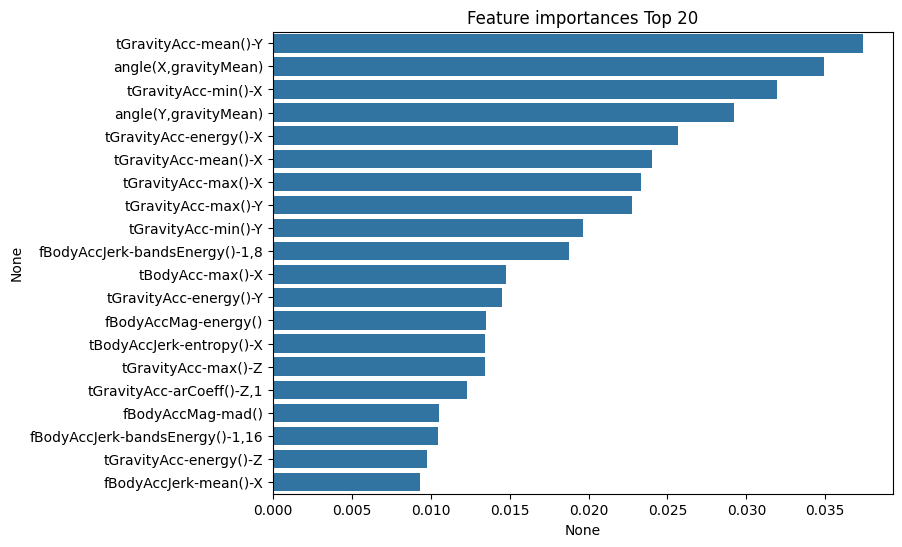

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

ftr_importances_values = rf_clf1.feature_importances_
ftr_importances = pd.Series(ftr_importances_values, index=X_train.columns)
ftr_top20 = ftr_importances.sort_values(ascending=False)[:20]

plt.figure(figsize=(8,6))
plt.title('Feature importances Top 20')
sns.barplot(x=ftr_top20, y=ftr_top20.index)
plt.show()

# **4.5 GBM(Gradient Boosting Machine)**

### **\# GMB의 개요 및 실습**

**부스팅 알고리즘:** 여러 개의 약한 학습기를 순차적으로 학습-예측하면서 잘못 예측한 데이터에 가중치 부여를 통해 오류를 개선해 나가면서 학습하는 방식

**에이다 부스트(AdaBoost):** 오류 데이터에 가중치를 부여하면서 부스팅을 수행하는 대표적인 알고리즘

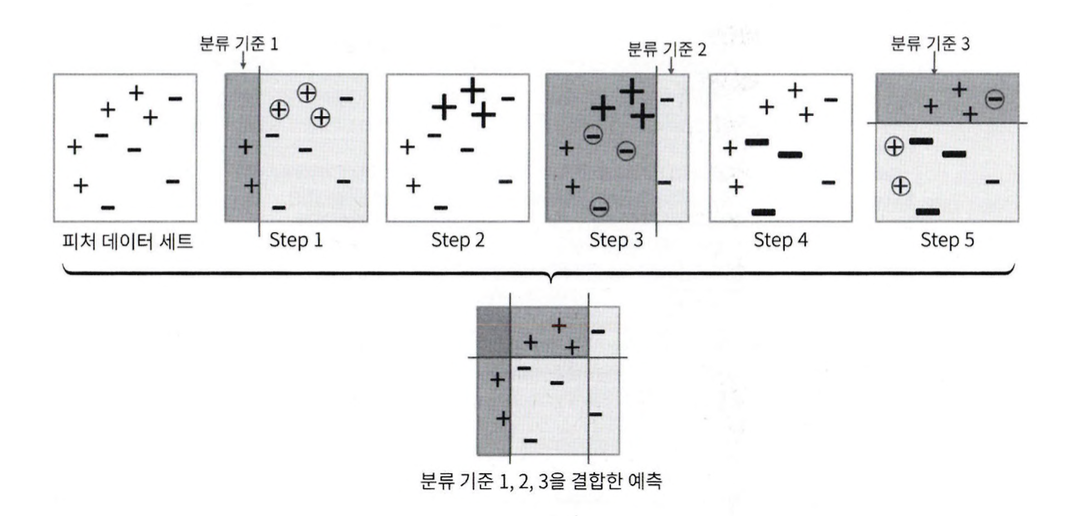

- GBM(Gradient Boost Machine)도 에이다부스트와 유사하나, 가중치 업데이트를 경사 하강법 (Gradient Descent)을 이용하는 것이 큰 차이

In [16]:
from sklearn.ensemble import GradientBoostingClassifier
import time
import warnings
warnings.filterwarnings('ignore')

X_train, X_test, y_train, y_test = get_human_dataset()

# GBM 수행 시간 측정을 위함.시작 시간 설정.
start_time = time.time()
gb_clf = GradientBoostingClassifier(random_state=0)
gb_clf.fit(X_train, y_train)
gb_pred = gb_clf.predict(X_test)
gb_accuracy = accuracy_score(y_test, gb_pred)

print('GBM 정확도: {0:.4f}'.format(gb_accuracy))
print("GBM 수행 시간: {0:.1f} 초".format(time.time() - start_time))

GBM 정확도: 0.9379
GBM 수행 시간: 1435.0 초


### **\# GBM 하이퍼 파라미터 소개**

\- loss: 경사 하강법에서 사용할 비용 함수를 지정

\- learning_rate: GBM이 학습을 진행할 때마다 적용하는 학습률, Weak learner가 순차적으로 오류 값을 보정해 나
가는 데 적용하는 계수

\- n_estimators: weak learner의 개수

\- subsample: weak learner가 학습에 사용하는 데이터의 샘플링 비율

# **4.6 XGBoost(eXtra Gradient Boost)**

### **\# XGBoost 개요**

**XGBoost:** GBM에 기반, GBM의 문제를 해결해서 각광받고 있음, 핵심 라이브러리는 C/C++로 작성되어 있음

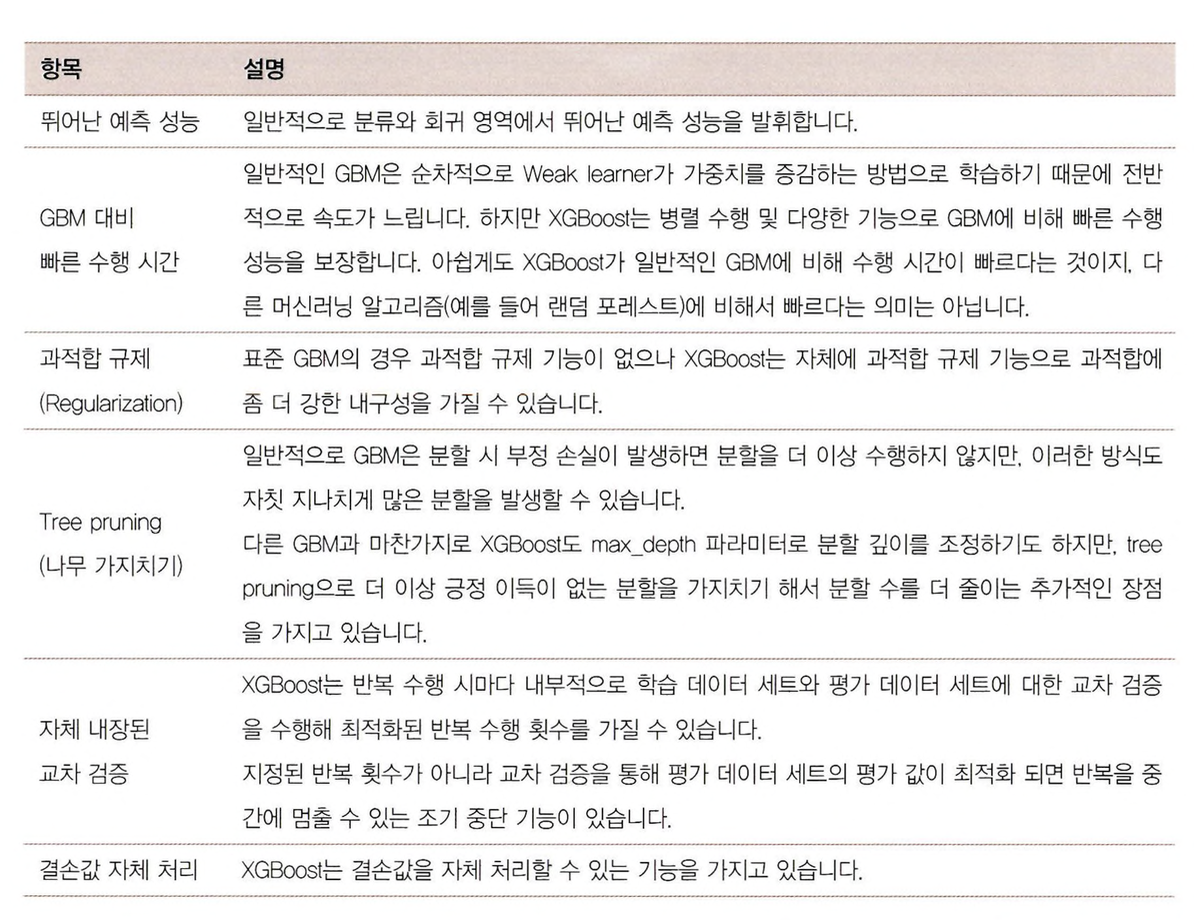

### **\# XGBoost 설치하기**

In [17]:
#pip install xgboost==1.5.0

In [18]:
import xgboost as xgb
from xgboost import XGBClassifier

### **\# 파이썬 래퍼 XGBoost 하이퍼 파라미터**

**일반 파라미터:** 일반적으로 실행 시 스레드의 개수나 silent 모드 등의 선택을 위한 파라미터


**부스터 파라미터:** 트리 최적화,부스팅, regularization 등과 관련 파라미터 등을 지칭

**학습 태스크 파라미터:** 학습 수행 시의 객체 함수, 평가를 위한 지표 등을 설정하는 파라미터

In [19]:
import xgboost

print(xgboost.__version__)

3.4.1


### **\# 파이썬 래퍼 XGBoost 적용 - 위스콘신 유방암 예측**

In [20]:
import xgboost as xgb
from xgboost import plot_importance
import pandas as pd
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')

dataset = load_breast_cancer()
features= dataset.data
labels = dataset.target

cancer_df = pd.DataFrame(data=features, columns=dataset.feature_names)
cancer_df['target']= labels
cancer_df.head(3)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0


In [21]:
print(dataset.target_names)
print(cancer_df['target'].value_counts())

['malignant' 'benign']
target
1    357
0    212
Name: count, dtype: int64


<데이터 분할 및 슬라이싱>

In [22]:
# cancer_df에서 feature용 DataFrame과 Label용 Series 객체 추출
# 맨 마지막 칼럼이 Label임. Feature용 DataFrame은 cancer_df의 첫번째 칼럼에서 맨 마지막 두번째 칼럼까지를 :-1 슬라이싱으로 추출.
X_features = cancer_df.iloc[:, :-1 ]
y_label = cancer_df.iloc[:, -1 ]

# 전체 데이터 중 80%는 학습용 데이터, 20%는 테스트용 데이터 추출
X_train, X_test, y_train, y_test=train_test_split(X_features, y_label, test_size=0.2,random_state = 156 )
# 위에서 만든 X.train, y_train을 다시 쪼개서 90%는 학습과 10%는 검증용 데이터로 분리
X_tr, X_val, y_tr, y_val= train_test_split(X_train, y_train, test_size=0.1, random_state=156 )

print(X_train.shape , X_test.shape)
print(X_tr.shape, X_val.shape)

(455, 30) (114, 30)
(409, 30) (46, 30)


<DataFrame 기반의 학습 데이터 세트와
테스트 데이터 세트를 DMatrix로 변환>

In [24]:
#만약 구버전 XGBoost에서 DataFrame으로 DMatrix 생성이 안 될 경우 X_train.values로 넘파이 변환.
#학습, 검증, 테스트용 DMatrix를 생성.
dtr = xgb.DMatrix(data=X_tr, label=y_tr)
dval = xgb. DMatrix(data=X_val, label=y_val)
dtest = xgb.DMatrix(data=X_test, label=y_test)

<XGBoost의 하이퍼 파
라미터를 설정>

In [25]:
params = { 'max.depth':3,
          'eta': 0.05,
           'objective':'binary:logistic',
           'eval_metric':'logloss'
}
num_rounds = 400

<xgboost 모듈의 train()
함수를 호출하면 학습을 수행>

In [26]:
# 학습 데이터 셋은 'train' 또는 평가 데이터 셋은 'eval' 로 명기합니다.
eval_list = [(dtr,'train'),(dval,'eval')] # 또는 eval_list = [(dval/eval')] 만 명기해도 무방.

# 하이퍼 파라미터와 early stopping 파라미터를 train( ) 함수의 파라미터로 전달
xgb_model = xgb.train(params = params , dtrain=dtr , num_boost_round=num_rounds , \
                      early_stopping_rounds=50, evals=eval_list )

[0]	train-logloss:0.62387	eval-logloss:0.62838
[1]	train-logloss:0.58495	eval-logloss:0.60050
[2]	train-logloss:0.54966	eval-logloss:0.57614
[3]	train-logloss:0.51751	eval-logloss:0.55407
[4]	train-logloss:0.48808	eval-logloss:0.53310
[5]	train-logloss:0.46083	eval-logloss:0.51153
[6]	train-logloss:0.43570	eval-logloss:0.49302
[7]	train-logloss:0.41251	eval-logloss:0.47600
[8]	train-logloss:0.39106	eval-logloss:0.46076
[9]	train-logloss:0.37117	eval-logloss:0.44654
[10]	train-logloss:0.35195	eval-logloss:0.43265
[11]	train-logloss:0.33466	eval-logloss:0.42021
[12]	train-logloss:0.31853	eval-logloss:0.40903
[13]	train-logloss:0.30332	eval-logloss:0.39880
[14]	train-logloss:0.28925	eval-logloss:0.38921
[15]	train-logloss:0.27578	eval-logloss:0.38006
[16]	train-logloss:0.26285	eval-logloss:0.37089
[17]	train-logloss:0.25108	eval-logloss:0.36393
[18]	train-logloss:0.23992	eval-logloss:0.35722
[19]	train-logloss:0.22913	eval-logloss:0.34970
[20]	train-logloss:0.21898	eval-logloss:0.34270
[2

In [35]:
pred_probs = xgb_model.predict(dtest)
print('predict( ) 수행 결괏값을 10개만 표시, 예측 확률 값으로 표시됨')
print(np.round(pred_probs[:10],3))

# 예측 확률이 0.5보다 크면 1 ,그렇지 않으면 0으로 예측값 결정하여 List 객체인 preds에 저장
preds = [ 1 if x > 0.5 else 0 for x in pred_probs ]
print('예측값 10개만 표시:',preds[:10])

predict( ) 수행 결괏값을 10개만 표시, 예측 확률 값으로 표시됨
[0.96  0.006 0.62  0.186 0.979 0.999 0.998 0.997 0.997 0.002]
예측값 10개만 표시: [1, 0, 1, 0, 1, 1, 1, 1, 1, 0]


In [40]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

def get_clf_eval(y_test, pred, pred_proba):
  confusion=confusion_matrix(y_test,pred)
  accuracy=accuracy_score(y_test, pred)
  precision=precision_score(y_test, pred)
  recall=recall_score(y_test,pred)
  f1=f1_score(y_test, pred)
  roc_auc=roc_auc_score(y_test,pred)

  print('오차행렬')
  print(confusion)
  print('정확도:{0:.4f},정밀도:{1:.4f},재현율:{2:.4f},F1:{3:.4f}, AUC:{4:.4f}'.format(accuracy,precision,recall,f1,roc_auc))

get_clf_eval(y_test, preds, pred_probs)

오차행렬
[[34  3]
 [ 2 75]]
정확도:0.9561,정밀도:0.9615,재현율:0.9740,F1:0.9677, AUC:0.9465


<xgboost 패키지에 내장된 시각화 수행>

<Axes: title={'center': 'Feature importance'}, xlabel='Importance score', ylabel='Features'>

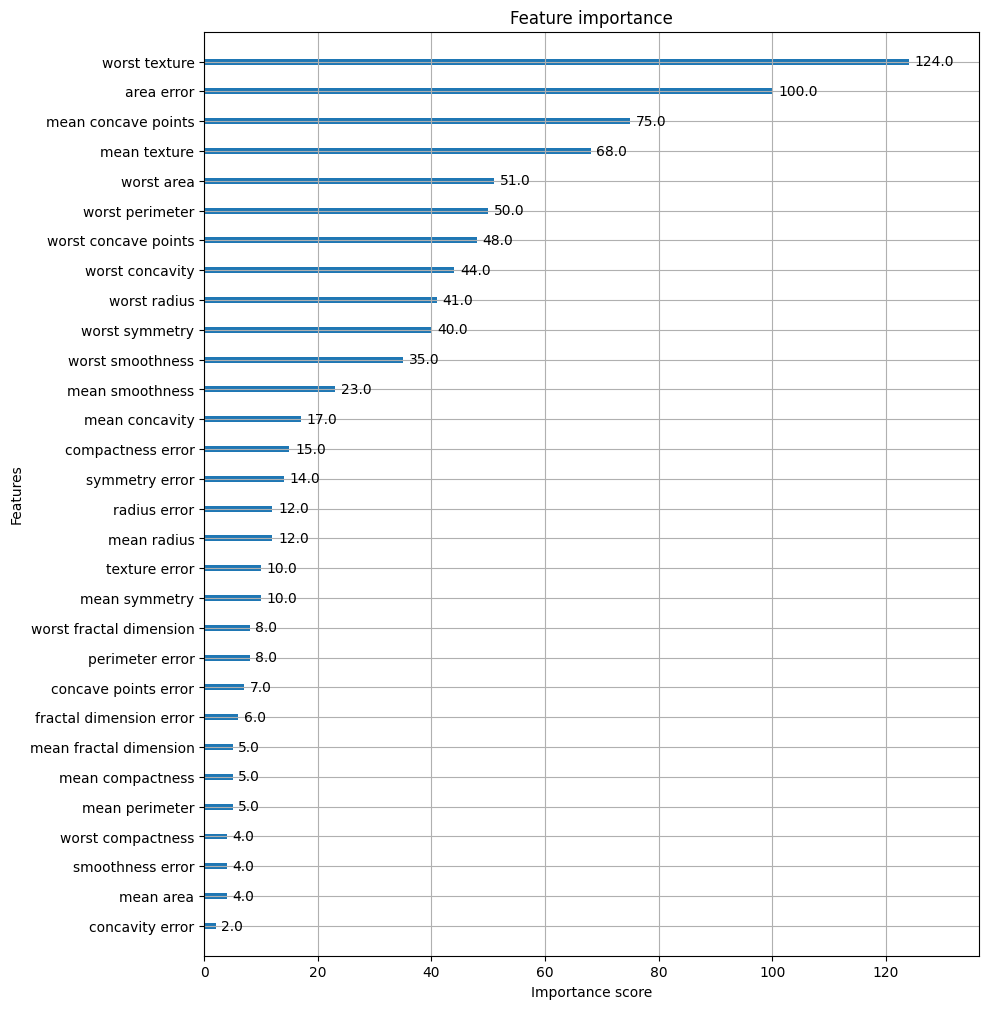

In [41]:
import matplotlib.pyplot as pit
%matplotlib inline

fig, ax = pit.subplots(figsize=(10, 12))
plot_importance(xgb_model, ax=ax)

-> xgb.cv의 반환값은 DataFrame 형태

### **\# 사이킷런 래퍼 XGBoost의 개요 및 적용**

- XGBoost 개발 그룹은 사이킷런의 프레임워크와 연동하기 위해 사이킷런 전용의 XGBoost 래퍼 클래스를 개발 -> 사이킷런의 기본 Estimator를 그대로 상속, 알고리즘 클래스만 XGboost 래퍼 클래스로 바꾸면 기존 프로그램을 그대로 사용할 수 있음

- 분류를 위한 래퍼 클래스인 XGBClassifier, 회귀를 위한 래퍼 클래스인 XGBRegressor이 있음



In [43]:
#사이킷런 래퍼 XGBoost 클래스인 XGBClassifier 임포트
from xgboost import XGBClassifier

# Warning 메시지를 없애기 위해 eval.metric 값을 XGBClassifier 생성 인자로 입력
xgb_wrapper = XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=3,eval_metric='logloss')
xgb_wrapper.fit(X_train, y_train, verbose=True)
w_preds = xgb_wrapper.predict(X_test)
w_pred_proba = xgb_wrapper.predict_proba(X_test)[:,1]

In [44]:
get_clf_eval(y_test , w_preds, w_pred_proba)

오차행렬
[[35  2]
 [ 1 76]]
정확도:0.9737,정밀도:0.9744,재현율:0.9870,F1:0.9806, AUC:0.9665


-> 파이썬 래퍼 XGBoost보다 더 좋은 평가 결과가 나옴

<사이킷런 래퍼XGBoost에서 조기 중단>

In [48]:
from xgboost import XGBClassifier

xgb_wrapper = XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=3,eval_metric="logloss",early_stopping_rounds=50)
evals = [(X_tr, y_tr), (X_val, y_val)]
xgb_wrapper.fit(X_tr, y_tr,eval_set=evals, verbose=True)
ws50_preds = xgb_wrapper.predict(X_test)
ws50_pred_proba = xgb_wrapper.predict_proba(X_test)[:,1]

[0]	validation_0-logloss:0.62473	validation_1-logloss:0.63225
[1]	validation_0-logloss:0.58662	validation_1-logloss:0.60730
[2]	validation_0-logloss:0.55210	validation_1-logloss:0.58562
[3]	validation_0-logloss:0.52058	validation_1-logloss:0.56615
[4]	validation_0-logloss:0.49155	validation_1-logloss:0.54542
[5]	validation_0-logloss:0.46491	validation_1-logloss:0.53043
[6]	validation_0-logloss:0.43969	validation_1-logloss:0.51101
[7]	validation_0-logloss:0.41648	validation_1-logloss:0.49373
[8]	validation_0-logloss:0.39503	validation_1-logloss:0.47735
[9]	validation_0-logloss:0.37517	validation_1-logloss:0.46266
[10]	validation_0-logloss:0.35673	validation_1-logloss:0.44940
[11]	validation_0-logloss:0.33938	validation_1-logloss:0.43843
[12]	validation_0-logloss:0.32276	validation_1-logloss:0.42597
[13]	validation_0-logloss:0.30774	validation_1-logloss:0.41552
[14]	validation_0-logloss:0.29356	validation_1-logloss:0.40645
[15]	validation_0-logloss:0.27989	validation_1-logloss:0.39635
[1

In [49]:
get_clf_eval(y_test , ws50_preds, ws50_pred_proba)

오차행렬
[[35  2]
 [ 2 75]]
정확도:0.9649,정밀도:0.9740,재현율:0.9740,F1:0.9740, AUC:0.9600


< early_stopping_rounds를
10으로 설정>

In [50]:
# early_stopping_ro니nds를 10으로 설정하고 재학습.
xgb_wrapper=XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=3, early_stopping_rounds=10, eval_metric='logloss')

xgb_wrapper.fit(X_tr,y_tr, eval_set=evals, verbose=True)

ws10_preds=xgb_wrapper.predict(X_test)

ws10_preds_proba=xgb_wrapper.predict_proba(X_test)[:,1]

get_clf_eval(y_test, ws10_preds, ws10_preds_proba)

[0]	validation_0-logloss:0.62473	validation_1-logloss:0.63225
[1]	validation_0-logloss:0.58662	validation_1-logloss:0.60730
[2]	validation_0-logloss:0.55210	validation_1-logloss:0.58562
[3]	validation_0-logloss:0.52058	validation_1-logloss:0.56615
[4]	validation_0-logloss:0.49155	validation_1-logloss:0.54542
[5]	validation_0-logloss:0.46491	validation_1-logloss:0.53043
[6]	validation_0-logloss:0.43969	validation_1-logloss:0.51101
[7]	validation_0-logloss:0.41648	validation_1-logloss:0.49373
[8]	validation_0-logloss:0.39503	validation_1-logloss:0.47735
[9]	validation_0-logloss:0.37517	validation_1-logloss:0.46266
[10]	validation_0-logloss:0.35673	validation_1-logloss:0.44940
[11]	validation_0-logloss:0.33938	validation_1-logloss:0.43843
[12]	validation_0-logloss:0.32276	validation_1-logloss:0.42597
[13]	validation_0-logloss:0.30774	validation_1-logloss:0.41552
[14]	validation_0-logloss:0.29356	validation_1-logloss:0.40645
[15]	validation_0-logloss:0.27989	validation_1-logloss:0.39635
[1

<plotjmportance() API에 사이킷런 래퍼 클래스 이용>

<Axes: title={'center': 'Feature importance'}, xlabel='Importance score', ylabel='Features'>

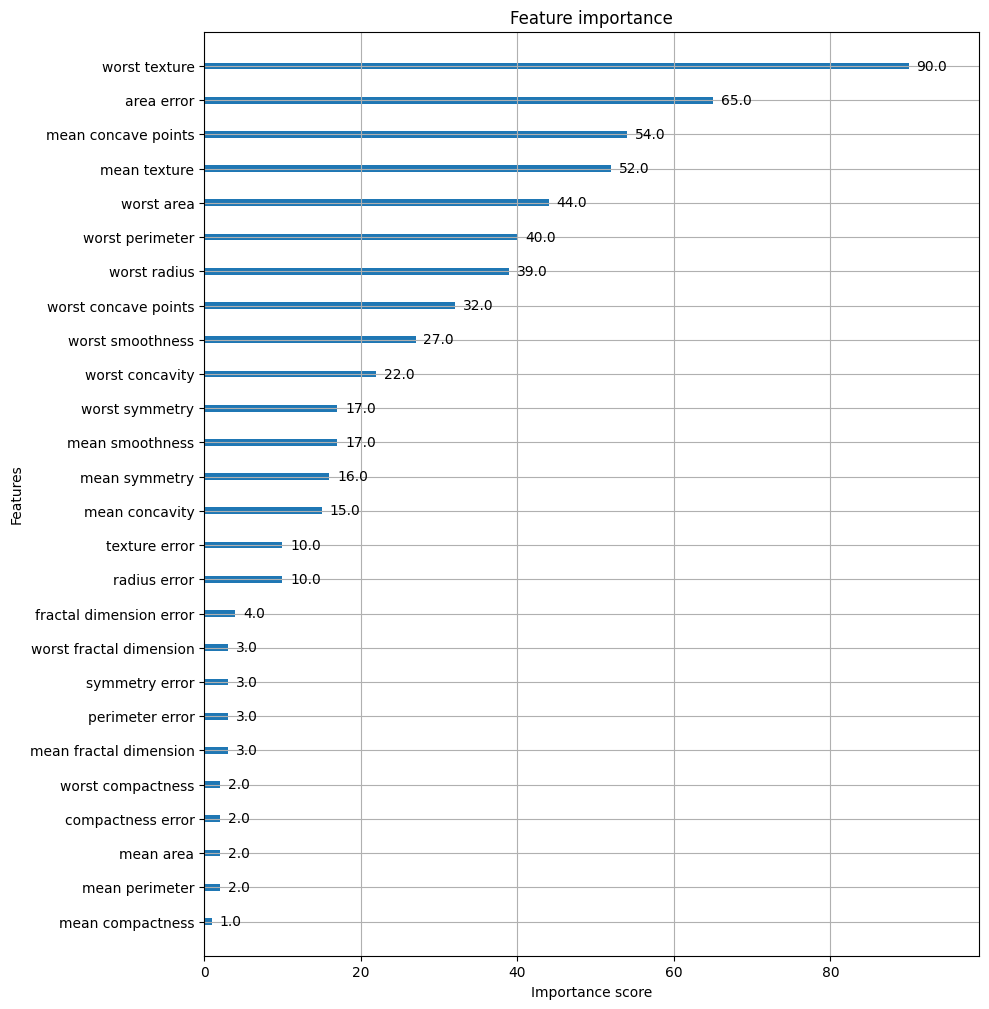

In [51]:
from xgboost import plot_importance
import matplotlib.pyplot as pit
%matplotlib inline

fig, ax = pit.subplots(figsize=(10, 12))
# 사이킷런 래퍼 클래스를 입력해도 무방
plot_importance(xgb_wrapper, ax=ax)